# Qualification des demandes Artelio — exploration, modélisation, évaluation

**Objectif.** À partir du message d'un client (« fuite sous l'évier, ça coule partout »), prédire :
- le **métier** (7 classes) pour orienter vers le bon artisan ;
- l'**urgence** (4 niveaux ordonnés) pour prioriser l'intervention.

**Contraintes métier** (cahier des charges, `docs/CAHIER_DES_CHARGES_IA.md`) : ne jamais sous-estimer gravement une
urgence, envoyer en revue humaine ce qui est incertain, expliquer la décision (AI Act), répondre en moins de 300 ms
sur CPU.

**Plan.** 1. Données · 2. Le piège des gabarits · 3. Démarche v1 → v3 · 4. Évaluation du champion (intervalles de
confiance) · 5. Calibration et revue humaine · 6. Robustesse et équité · 7. Explicabilité · 8. Analyse d'erreurs · 9. Limites

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from artelio_ia import donnees as d, evaluation as ev, registre
from artelio_ia.config import DOSSIER_MODELES, URGENCES, GRAINE
from artelio_ia.modele import candidats
pd.set_option("display.precision", 3); plt.rcParams["figure.dpi"] = 110

jeu = d.charger()                                   # dernière version publiée par le pipeline (bloc 3), empreinte vérifiée
donnees = jeu.donnees
train, test_temporel = d.decouper_temporel(donnees)
validation, test_final = d.charger_hors_gabarits("validation"), d.charger_hors_gabarits("test")
print(f"Version {jeu.version} : {len(donnees)} demandes | train {len(train)} | test temporel {len(test_temporel)}")
print(f"Validation hors gabarits : {len(validation)} | test final hors gabarits : {len(test_final)}")

/usr/local/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


Version 20261026T030007Z : 7380 demandes | train 5832 | test temporel 1548
Validation hors gabarits : 143 | test final hors gabarits : 90


## 1. Les données

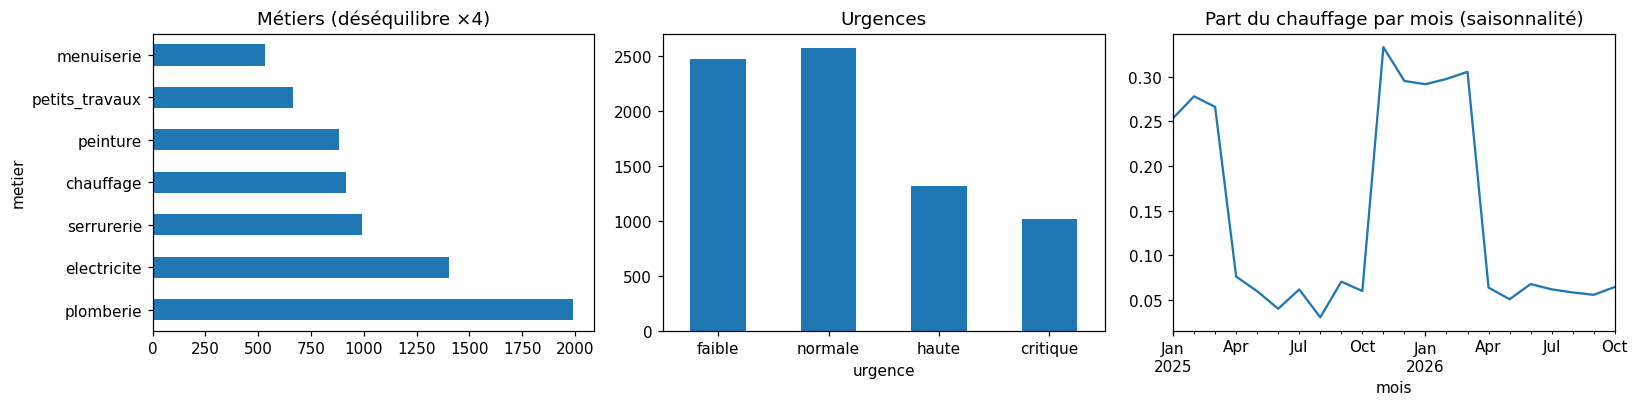

,count,mean,std,min,25%,50%,75%,max
nombre de mots,7380.0,13.524,3.591,4.0,11.0,14.0,16.0,26.0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
donnees["metier"].value_counts().plot.barh(ax=axes[0], title="Métiers (déséquilibre ×4)")
donnees["urgence"].value_counts().reindex(URGENCES).plot.bar(ax=axes[1], title="Urgences", rot=0)
(donnees.assign(mois=donnees["cree_le"].dt.to_period("M")).groupby("mois")["metier"]
 .apply(lambda s: (s == "chauffage").mean()).plot(ax=axes[2], title="Part du chauffage par mois (saisonnalité)"))
plt.tight_layout(); plt.show()
donnees["texte"].str.split().str.len().describe().to_frame("nombre de mots").T

**À retenir.** Classes déséquilibrées (→ `class_weight="balanced"` et F1 **macro**, qui donne le même poids à chaque
classe), forte saisonnalité du chauffage (→ dérive attendue chaque hiver, d'où la surveillance et le réentraînement),
textes courts (~15 mots).

## 2. Le piège des gabarits

Les données du pipeline sont synthétiques, générées à partir de gabarits de phrases. Un modèle TF-IDF entraîné
dessus obtient un score parfait en validation croisée… et s'effondre sur des textes formulés autrement.

In [3]:
tfidf = candidats(avec_plongements=False)["regression_logistique_C4.0"]
cv = StratifiedKFold(5, shuffle=True, random_state=GRAINE)
lignes = []
for cible in ("metier", "urgence"):
    score_cv = cross_val_score(tfidf, train["texte"], train[cible], cv=cv, scoring="f1_macro", n_jobs=2).mean()
    modele = clone(tfidf).fit(train["texte"], train[cible])
    lignes.append({"tâche": cible, "F1 macro — validation croisée": score_cv,
                   "F1 macro — validation hors gabarits": f1_score(validation[cible], modele.predict(validation["texte"]), average="macro")})
pd.DataFrame(lignes)

,tâche,F1 macro — validation croisée,F1 macro — validation hors gabarits
0,metier,1.0,0.740
1,urgence,1.0,0.511


La validation croisée mesure ici la capacité à **reconnaître les gabarits**, pas à comprendre une demande. D'où la
méthode d'évaluation retenue (détails dans `data/README.md`) :
- **validation hors gabarits** (143 textes écrits à la main) : sélection de modèle et barrière de promotion ;
- **test final hors gabarits** (90 textes, rédigés après le gel de la v2) : mesure uniquement, jamais pour décider.

## 3. Démarche : de la v1 à la v3

| Version | Changement | Pourquoi |
|---|---|---|
| v1 | TF-IDF (mots + caractères) + régression logistique, données du pipeline seules | référence |
| v2 | + enrichissement par **lexique métier**, + **garde-fous** déterministes sur les signaux de danger | diversité des formulations ; coût asymétrique des urgences ratées |
| v3 | + **plongements de phrases** (MiniLM multilingue) combinés au TF-IDF ; casse normalisée ; détection **hors domaine** ; copies **bruitées** | comprendre le sens sans mot commun ; robustesse |

Résultats sur le **test final** (mesures successives, toutes conservées dans MLflow) :

In [4]:
resultats_versions = pd.DataFrame([
    {"version": "v2 (TF-IDF + lexique + garde-fous)", "F1 métier": 0.800, "F1 urgence": 0.594, "rappel critique": 0.571, "sous-estimation grave": 0.044},
    {"version": "v3 (hybride TF-IDF + plongements)", "F1 métier": 0.785, "F1 urgence": 0.656, "rappel critique": 0.857, "sous-estimation grave": 0.000},
])
champion = registre.charger_local(DOSSIER_MODELES / "champion")
r = ev.metriques(champion, test_final)
resultats_versions.loc[len(resultats_versions)] = {"version": "champion livré (models/champion)", "F1 métier": r["metier"]["f1_macro"],
    "F1 urgence": r["urgence"]["f1_macro"], "rappel critique": r["urgence"]["rappel_critique"],
    "sous-estimation grave": r["urgence"]["sous_estimation_grave"]}
resultats_versions

,version,F1 métier,F1 urgence,rappel critique,sous-estimation grave
0,v2 (TF-IDF + lexique + garde-fous),0.800,0.594,0.571,0.044
1,v3 (hybride TF-IDF + plongements),0.785,0.656,0.857,0.000
2,champion livré (models/champion),0.781,0.639,0.786,0.011


## 4. Évaluation du champion, avec intervalles de confiance

Les jeux hors gabarits sont petits : un intervalle de confiance (bootstrap, 1 000 tirages) évite de sur-interpréter
quelques points d'écart.

In [5]:
def bootstrap(y, p, metrique, n=1000, graine=0):
    rng = np.random.default_rng(graine); y, p = np.asarray(y), np.asarray(p); scores = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); scores.append(metrique(y[i], p[i]))
    return np.percentile(scores, [2.5, 97.5])

def rappel_critique(y, p):
    m = y == "critique"; return (p[m] == "critique").mean() if m.any() else np.nan

lignes = []
for nom, jeu_eval in (("validation", validation), ("test final", test_final)):
    preds = champion.predire(jeu_eval["texte"].tolist())
    pm, pu = np.array([x.metier for x in preds]), np.array([x.urgence for x in preds])
    for libelle, y, p, f in (("F1 macro métier", jeu_eval["metier"], pm, lambda a, b: f1_score(a, b, average="macro")),
                             ("F1 macro urgence", jeu_eval["urgence"], pu, lambda a, b: f1_score(a, b, average="macro")),
                             ("rappel urgences critiques", jeu_eval["urgence"], pu, rappel_critique)):
        bas, haut = bootstrap(y, p, f)
        lignes.append({"jeu": nom, "métrique": libelle, "valeur": f(np.asarray(y), p), "IC 95 % bas": bas, "IC 95 % haut": haut})
pd.DataFrame(lignes)

,jeu,métrique,valeur,IC 95 % bas,IC 95 % haut
0,validation,F1 macro métier,0.908,0.854,0.951
1,validation,F1 macro urgence,0.722,0.631,0.796
2,validation,rappel urgences critiques,1.000,1.000,1.000
3,test final,F1 macro métier,0.781,0.675,0.860
4,test final,F1 macro urgence,0.639,0.527,0.737
5,test final,rappel urgences critiques,0.786,0.545,1.000


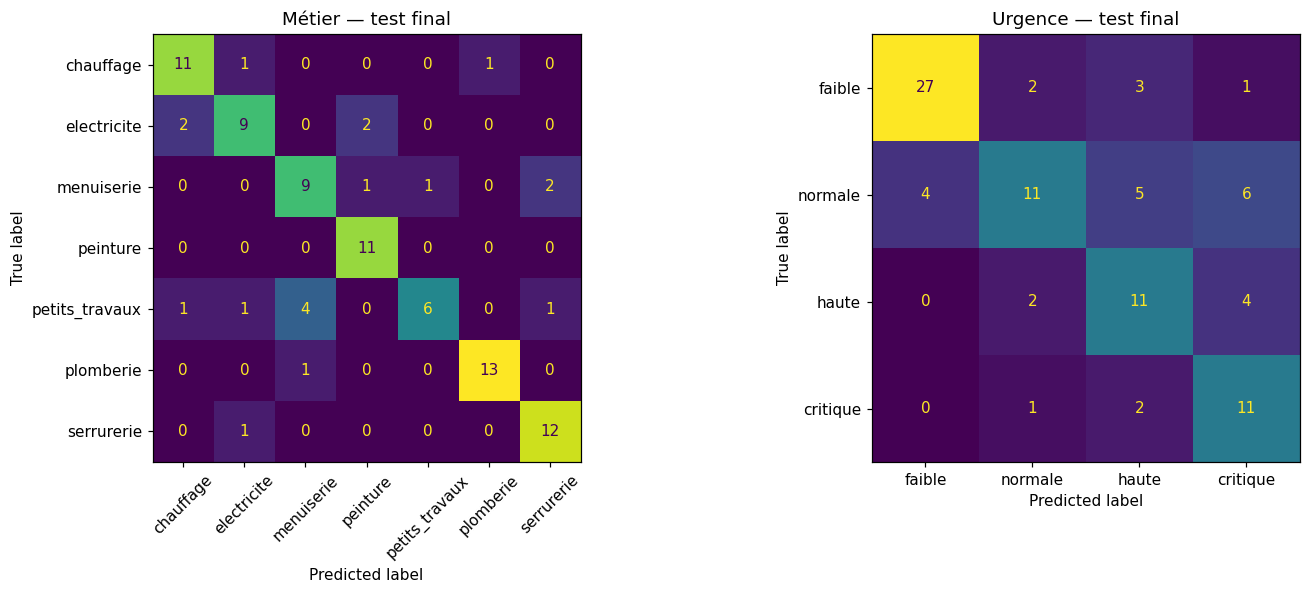

,precision,recall,f1-score,support
faible,0.871,0.818,0.844,33.0
normale,0.688,0.423,0.524,26.0
haute,0.524,0.647,0.579,17.0
critique,0.500,0.786,0.611,14.0


In [6]:
preds = champion.predire(test_final["texte"].tolist())
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(test_final["metier"], [p.metier for p in preds], ax=axes[0], xticks_rotation=45, colorbar=False)
ConfusionMatrixDisplay.from_predictions(test_final["urgence"], [p.urgence for p in preds], labels=URGENCES, ax=axes[1], colorbar=False)
axes[0].set_title("Métier — test final"); axes[1].set_title("Urgence — test final"); plt.tight_layout(); plt.show()
pd.DataFrame(r["urgence"]["par_classe"]).T.loc[URGENCES, ["precision", "recall", "f1-score", "support"]]

**Lecture.** Les confusions d'urgence se font surtout entre niveaux **voisins** (normale ↔ haute) ; la sous-estimation
**grave** (critique classée normale ou faible) est l'erreur que la politique de décision cherche à éliminer.

## 5. Calibration et politique de revue humaine

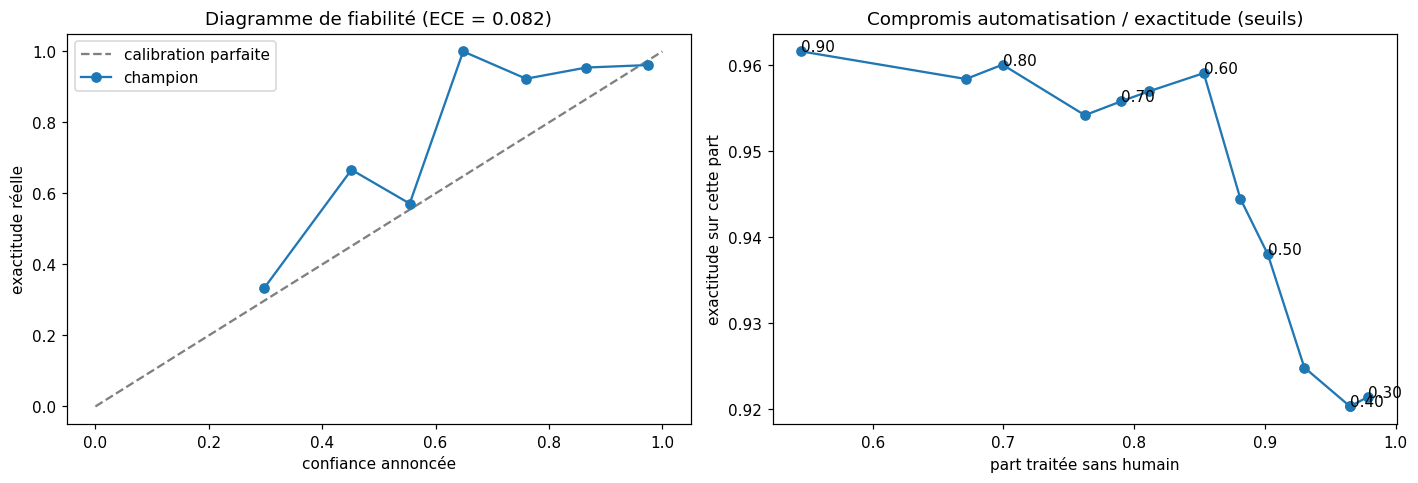

In [7]:
probas = champion.modele_metier.predict_proba(validation["texte"].tolist())
confiance = probas.max(axis=1); correct = np.array(champion.modele_metier.classes_)[probas.argmax(1)] == validation["metier"].to_numpy()
tranches = np.linspace(0, 1, 11); centres, exactitudes = [], []
for bas, haut in zip(tranches[:-1], tranches[1:], strict=True):
    m = (confiance > bas) & (confiance <= haut)
    if m.sum() >= 3: centres.append(confiance[m].mean()); exactitudes.append(correct[m].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="calibration parfaite"); axes[0].plot(centres, exactitudes, "o-", label="champion")
axes[0].set(xlabel="confiance annoncée", ylabel="exactitude réelle", title=f"Diagramme de fiabilité (ECE = {ev.erreur_calibration(probas, validation['metier'].to_numpy(), list(champion.modele_metier.classes_)):.3f})"); axes[0].legend()
compromis = ev.compromis_couverture(champion, validation)
axes[1].plot(compromis["couverture_automatique"], compromis["exactitude_automatique"], "o-")
for _, ligne in compromis.iloc[::2].iterrows(): axes[1].annotate(f"{ligne.seuil:.2f}", (ligne.couverture_automatique, ligne.exactitude_automatique))
axes[1].set(xlabel="part traitée sans humain", ylabel="exactitude sur cette part", title="Compromis automatisation / exactitude (seuils)")
plt.tight_layout(); plt.show()

Le seuil de confiance (0,55) a été **fixé a priori par le métier puis mesuré** (et non optimisé sur le test) :
en dessous, la demande part en revue humaine. Les demandes traitées automatiquement sont nettement plus exactes que
celles envoyées en revue — c'est le but : l'humain se concentre là où le modèle doute.

In [8]:
r_val = ev.metriques(champion, validation)["revue_humaine"]
pd.Series({"part en revue humaine": r_val["taux"], "exactitude métier — traitement automatique": r_val["exactitude_metier_automatique"],
           "exactitude métier — demandes en revue": r_val["exactitude_metier_en_revue"]}).to_frame("validation")

,validation
part en revue humaine,0.196
exactitude métier — traitement automatique,0.939
exactitude métier — demandes en revue,0.786


## 6. Robustesse et équité

In [9]:
ev.robustesse(champion, validation)

,perturbation,exactitude_metier,exactitude_urgence,taux_revue_humaine
0,original,0.909,0.748,0.196
1,sans_accents,0.874,0.748,0.203
2,majuscules,0.909,0.748,0.196
3,fautes_de_frappe,0.797,0.657,0.413
4,telephone_ajoute,0.874,0.699,0.483
5,debut_seulement,0.783,0.706,0.273
6,bruit_politesse,0.881,0.790,0.273


Le modèle résiste aux accents oubliés, aux majuscules (après correction de la casse des plongements : -15 points
avant), aux politesses et aux numéros de téléphone ajoutés. Les fautes de frappe denses restent le cas le plus
difficile, d'où l'entraînement sur des copies bruitées. **Équité** : le modèle n'utilise **que le texte** (ni adresse,
ni département, ni identité) ; on vérifie qu'aucun canal n'est nettement moins bien servi (les messages vocaux
transcrits et le téléphone sont souvent le fait de personnes moins à l'aise avec l'écrit) :

In [10]:
pd.concat([ev.par_tranche(champion, validation, "canal").assign(jeu="validation"),
           ev.par_tranche(champion, test_final, "canal").assign(jeu="test final")]).set_index(["jeu", "canal"])

n  exactitude_metier  exactitude_urgence  \
jeu        canal                                                  
validation app        45              0.889               0.711   
           telephone  17              0.824               0.765   
           vocal       8              1.000               0.875   
           web        73              0.932               0.753   
test final app        31              0.677               0.613   
           telephone  12              0.833               0.750   
           vocal       6              1.000               0.833   
           web        41              0.829               0.659   

                      taux_revue_humaine  
jeu        canal                          
validation app                     0.156  
           telephone               0.294  
           vocal                   0.250  
           web                     0.192  
test final app                     0.387  
           telephone               0.417  
           vocal                   0.333  
           web                     0.366

## 7. Explicabilité

Poids des termes les plus caractéristiques de chaque métier (partie TF-IDF « mots » de la régression logistique) :

In [11]:
vect, clf = champion.modele_metier.named_steps["vect"], champion.modele_metier.named_steps["clf"]
noms = vect.get_feature_names_out(); mots = np.array([n.startswith("mots__") for n in noms])
pd.DataFrame({classe: [noms[j].removeprefix("mots__") for j in np.argsort(-np.where(mots, clf.coef_[i], -np.inf))[:8]]
              for i, classe in enumerate(clf.classes_)})

,chauffage,electricite,menuiserie,peinture,petits_travaux,plomberie,serrurerie
0,chauffant,ajouter,vitre,repeindre,joints,mitigeur,serrure
1,plancher,prise,sur mesure,enduit,monter,bonde,verrou
2,plancher chauffant,vmc,mesure,fissuré,appui,odeur,poser un
3,gargouille,clignote,remplacer une,cage,barre,robinet,cylindre
4,cumulus,prises,sur,cage escalier,est monter,fuit,accroche
5,temps,plafonnier,parquet,et,barre appui,égout,un verrou
6,le cumulus,spots,une porte,boiseries,fixer,odeur égout,changer
7,chauffe,ajouter des,velux,traces,est assembler,goutte,et ferme


In [12]:
for texte in ["Ma fille de 6 ans est restée enfermée dans la salle de bain", "Le radiateur de la chambre gargouille et chauffe mal"]:
    p = champion.predire([texte], expliquer=True)[0]
    print(f"{texte}\n  → {p.metier} ({p.proba_metier:.0%}), urgence {p.urgence}, revue humaine : {p.revue_humaine} {p.motifs_revue}")
    print("   termes :", ", ".join(f"{e['terme']} ({e['contribution']:+.2f})" for e in p.explication), "\n")

Ma fille de 6 ans est restée enfermée dans la salle de bain
  → serrurerie (47%), urgence haute, revue humaine : True ['confiance_metier_faible']
   termes : (sens global de la phrase) (+1.20), la (+0.08), dans la (+0.04), dans (+0.03), bain (+0.02), de bain (+0.02) 



Le radiateur de la chambre gargouille et chauffe mal
  → chauffage (100%), urgence normale, revue humaine : False []
   termes : (sens global de la phrase) (+4.59), gargouille (+0.42), radiateur (+0.19), chauffe (+0.18), le radiateur (+0.17), chauffe mal (+0.07) 



La contribution « sens global de la phrase » (plongements) est souvent la plus forte : c'est elle qui permet de
reconnaître « ma fille est enfermée » sans mot-clé de serrurerie. L'API renvoie cette explication avec chaque prédiction.

## 8. Analyse d'erreurs (jeu de validation)

In [13]:
preds_val = champion.predire(validation["texte"].tolist())
erreurs = validation.assign(predit=[p.metier for p in preds_val], confiance=[p.proba_metier for p in preds_val],
                            revue=[p.revue_humaine for p in preds_val])
erreurs = erreurs[erreurs["predit"] != erreurs["metier"]]
print(f"{len(erreurs)} erreurs de métier sur {len(validation)} ; {erreurs['revue'].mean():.0%} d'entre elles partent en revue humaine")
erreurs[["texte", "metier", "predit", "confiance", "revue"]].sort_values("confiance", ascending=False)

13 erreurs de métier sur 143 ; 46% d'entre elles partent en revue humaine


,texte,metier,predit,confiance,revue
128,Changer la boîte aux lettres qui a été arrachée,petits_travaux,serrurerie,0.982,False
38,Le radiateur électrique de la chambre ne chauf...,electricite,chauffage,0.975,False
91,Vernir le parquet du séjour qui est terne,peinture,menuiserie,0.951,False
3,"Ballon d'eau chaude qui fuit par le bas, il y ...",plomberie,chauffage,0.858,False
133,Poser une rampe pour fauteuil roulant à l'entr...,petits_travaux,menuiserie,0.771,False
17,"Petite trace d'humidité sous l'évier, rien ne ...",plomberie,chauffage,0.598,False
141,"Installer des cache-prises et bloque-portes, j...",petits_travaux,electricite,0.555,False
40,"Coupure de courant partielle, le congélateur e...",electricite,chauffage,0.526,True
36,Poser un lustre au plafond de la salle à mange...,electricite,peinture,0.484,True
117,Pose d'une terrasse en bois,menuiserie,petits_travaux,0.459,True


Les erreurs restantes sont en majorité des **cas ambigus par nature** (ballon d'eau chaude : plomberie ou
chauffage ? radiateur électrique : électricité ou chauffage ? VMC) — un conseiller hésiterait aussi — et une bonne part
part déjà en revue humaine.

## 9. Limites et prochaines étapes

1. **Données synthétiques** : la vraie performance ne sera connue qu'en production, via le **taux de correction
   humaine** suivi en continu. Les corrections du support deviendront les nouvelles données d'entraînement.
2. **Petits jeux de test** : intervalles de confiance larges ; le test final a été mesuré plusieurs fois au fil des
   versions (déclaré) : la prochaine itération devra utiliser un **nouveau** jeu de test, idéalement de vraies demandes.
3. **Urgence** : la plus difficile (F1 ≈ 0,65) car elle dépend du contexte (« il gèle et ma mère est âgée ») ; d'où les
   garde-fous et la revue humaine. Piste : affiner un modèle français (CamemBERT) quand de vraies données seront disponibles.
4. **Coût** : plongements = ~80 ms par demande sur CPU (contre ~3 ms en TF-IDF seul), largement sous l'objectif de 300 ms.